# 292. Two short linked HP words instead of one long one: a kill test on Pfam seed pairs

**Question.** [Notebook 232](232_mismatch_tolerant_seed_extend.ipynb) found that the longest
exact run of shared hydrophobic/polar (HP) classes between true homologs at 20–30% identity
is about 12 residues, so a single exact HP word of 20 or more letters rarely survives. Does
a key made of two short exact words, each of which only has to survive 6–10 residues,
recover more true pairs than 232's single 10-residue seed at the same false-positive rate?

**The construct.** Each short exact word is an *anchor*; the residues between the two
anchors are the *gap*. Two anchors plus the gap rule make one key, a linked word pair
(Sahlin 2021 calls this a strobemer, see [`292_prior_art.md`](292_prior_art.md)). Three gap
rules: the gap is stored exactly (`exact`), stored in 3-residue bins (`binned3`), or not
stored at all and only has to lie inside the window (`none`). Two ways to pick keys: every
anchor pair inside the window (`all`, many keys per position), or one partner per position
picked by Sahlin's randstrobe hash rule, separately in each sequence (`rand`, one key per
position, which an index can afford).

**Decision this informs.** Whether kmerseek's index should store linked HP word pairs
instead of single k-mers. Nothing in kmerseek changes unless the test passes; on a pass the
next step is a one-page design note, not code.

**Rule, fixed before the run** (from the task brief, 2026-10-14):

- PASS: in the 20–30% identity bin, the chosen linked-pair setting recovers at least 10
  percentage points more true pairs than the better of B1 and B2 at the 0.001 threshold,
  and the two bootstrap 95% intervals do not overlap.
- KILL: no linked-pair setting beats the better of B1 and B2 in any identity bin outside
  the bootstrap interval.
- Anything else: report, and do not touch the index.

The setting is chosen on a random half of the pairs (by recall at 20–30% identity) and every
reported number comes from the other half.

**Data, all from notebook 232** (written down here before any result):

- *True pairs*: 60,000 pairs of Pfam 38.2 seed-alignment members with at least 50 aligned
  columns, sampled from `~/data/pfam/230_pfam_seed_pair_alignments.parquet` (polars sample,
  seed 0). Per identity bin: <20% 6,655; 20–30% 15,130; 30–40% 13,872; 40–60% 16,862;
  ≥60% 7,481. Identity is identical residues over aligned columns (`seqid_ali`).
- *Null pairs*: each true pair with the target's residues shuffled along its own alignment
  row (gaps stay where they are, so composition and gap pattern are kept), two shuffles per
  pair: 120,000 null comparisons in all, 60,000 in each half. That is above the 20,000 the
  0.001 threshold needs to rest on at least 20 events, so the null was not enlarged.
- *One comparison*: one query–target pair (real or shuffled), scored only on the pair's own
  alignment: a seed or anchor counts only where it sits on aligned columns. Off-diagonal
  word matches are ignored, as in 232.
- *Threshold*: the 99.9th percentile of the pooled null scores (taking the higher of two
  neighbouring values), recall = share of true pairs scoring *strictly above* it. This is
  232's rule; because scores are whole numbers the achieved null rate is at or below 0.001,
  and it is printed for every setting.
- *Alphabet*: `hp_thomas_dill2`, hydrophobic `ACFILMVWY`, polar `DEGHKNPQRST` (X ends a
  word). Extension: +1 per column whose HP classes match, −2 per mismatch, a gap column ends
  a segment (232's penalty 2).
- *Baselines*: B1 = 232's 10-residue seed with extension; B2 = an 8-residue seed with the
  same extension, so linking is charged against a shorter single seed as well as a longer
  one.
- *Linked-pair score*: each shared key is extended with the same step. A key's score is the
  best total of at most two non-overlapping gap-free segments that together contain both
  anchors (one segment when both anchors sit in one gap-free stretch and joining them pays).
  The pair's score is its best key; its no-extension score is the number of shared keys.

Code: [`linked_pairs_utils.py`](linked_pairs_utils.py) (scoring, tested against brute force
in `tests/test_linked_pairs_utils.py`); scores from
`scripts/linked_pairs_on_alignments.py`; Swiss-Prot key rates from
`scripts/linked_pairs_key_spectrum.py`. No kmerseek run; everything is Python on the
laptop.

In [1]:
import sys
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from matplotlib.patches import Rectangle

sys.path.insert(0, str(Path.cwd()))
import hp_conservation_utils as hc
import linked_pairs_utils as lp
import pubfig as pf
import seed_extend_utils as se

pf.use_style()
pl.Config.set_tbl_rows(80)
pl.Config.set_tbl_cols(20)
pl.Config.set_tbl_width_chars(220)

FIG = Path("../figures")
SCORES = Path("/Users/olga/data/pfam/292_linked_pairs_scores.parquet")
SPECTRUM = Path("/Users/olga/data/pfam/292_linked_pairs_key_spectrum_swissprot.parquet")
NB232 = Path("/Users/olga/data/pfam/232_seed_extend_scores.parquet")
ALN = Path("/Users/olga/data/pfam/230_pfam_seed_pair_alignments.parquet")
FPR = 1e-3
N_BOOT = 1000
SPLIT_SEED = 292
SWISSPROT_PROTEINS = (
    572_970  # proteins in uniprot_sprot.fasta.gz, counted by the spectrum script
)
BINS = lp.BINS

# One colour per meaning, kept across all three figures.
COLOR = {
    "B1": pf.OKABE_ITO["blue"],  # 232's 10-residue seed
    "B2": pf.OKABE_ITO["sky_blue"],  # 8-residue seed
    "linked": pf.OKABE_ITO["vermillion"],  # chosen linked pair, with extension
    "linked_count": pf.OKABE_ITO["orange"],  # chosen linked pair, key count only
    "exact": pf.OKABE_ITO["bluish_green"],  # Fig. 3 gap rules
    "binned3": pf.OKABE_ITO["reddish_purple"],
    "none": pf.OKABE_ITO["black"],
}
TREAT_LABEL = {
    "exact": "gap stored exactly",
    "binned3": "gap in 3-residue bins",
    "none": "gap not stored",
}


def plain(setting: str) -> str:
    m, a, g, t = next(x for x in lp.ALL_SETTINGS if lp.setting_name(*x) == setting)
    pick = "every pair of" if m == "all" else "randstrobe pairs of"
    return f"{pick} {a}-letter anchors, gap up to {g}, {TREAT_LABEL[t]}"


MODE_LABEL = {
    "all": "every anchor pair in the window",
    "rand": "one partner per position (randstrobe)",
}

d = hc.add_identity_bin(pl.read_parquet(SCORES))
n_pairs = d.filter(pl.col("kind") == "real").height
print(f"{n_pairs:_} true pairs, {d.height - n_pairs:_} null comparisons")
print(
    d.filter(pl.col("kind") == "real")
    .group_by("identity_bin")
    .len()
    .sort("identity_bin")
)

LINKED = [lp.setting_name(*s) for s in lp.ALL_SETTINGS]
COLS = (
    ["B1_ext", "B2_ext", "seed10_count", "seed8_count"]
    + [f"{s}_ext" for s in LINKED]
    + [f"{s}_count" for s in LINKED]
)

60_000 true pairs, 120_000 null comparisons
shape: (5, 2)
┌──────────────┬───────┐
│ identity_bin ┆ len   │
│ ---          ┆ ---   │
│ enum         ┆ u32   │
╞══════════════╪═══════╡
│ <20%         ┆ 6655  │
│ 20-30%       ┆ 15130 │
│ 30-40%       ┆ 13872 │
│ 40-60%       ┆ 16862 │
│ >=60%        ┆ 7481  │
└──────────────┴───────┘


## 1. Gate 1: notebook 232's baseline, reproduced

B1 rescored from the alignments with this notebook's code, next to the scores 232 stored.
The rule for going on: every per-bin recall equal to 232's.

share of the 180,000 comparisons whose score equals 232's stored score:
shape: (1, 3)
┌──────────┬──────────┬────────┐
│ B1 equal ┆ B2 equal ┆ len    │
│ ---      ┆ ---      ┆ ---    │
│ f64      ┆ f64      ┆ u32    │
╞══════════╪══════════╪════════╡
│ 1.0      ┆ 1.0      ┆ 180000 │
└──────────┴──────────┴────────┘
shape: (5, 5)
┌──────────────┬─────────┬───────────┬─────────┬───────────┐
│ identity_bin ┆ B1 here ┆ B1 in 232 ┆ B2 here ┆ B2 in 232 │
│ ---          ┆ ---     ┆ ---       ┆ ---     ┆ ---       │
│ str          ┆ f64     ┆ f64       ┆ f64     ┆ f64       │
╞══════════════╪═════════╪═══════════╪═════════╪═══════════╡
│ <20%         ┆ 0.119   ┆ 0.119     ┆ 0.13    ┆ 0.13      │
│ 20-30%       ┆ 0.355   ┆ 0.355     ┆ 0.377   ┆ 0.377     │
│ 30-40%       ┆ 0.635   ┆ 0.635     ┆ 0.658   ┆ 0.658     │
│ 40-60%       ┆ 0.882   ┆ 0.882     ┆ 0.892   ┆ 0.892     │
│ >=60%        ┆ 0.986   ┆ 0.986     ┆ 0.987   ┆ 0.987     │
└──────────────┴─────────┴───────────┴─────────┴───────────

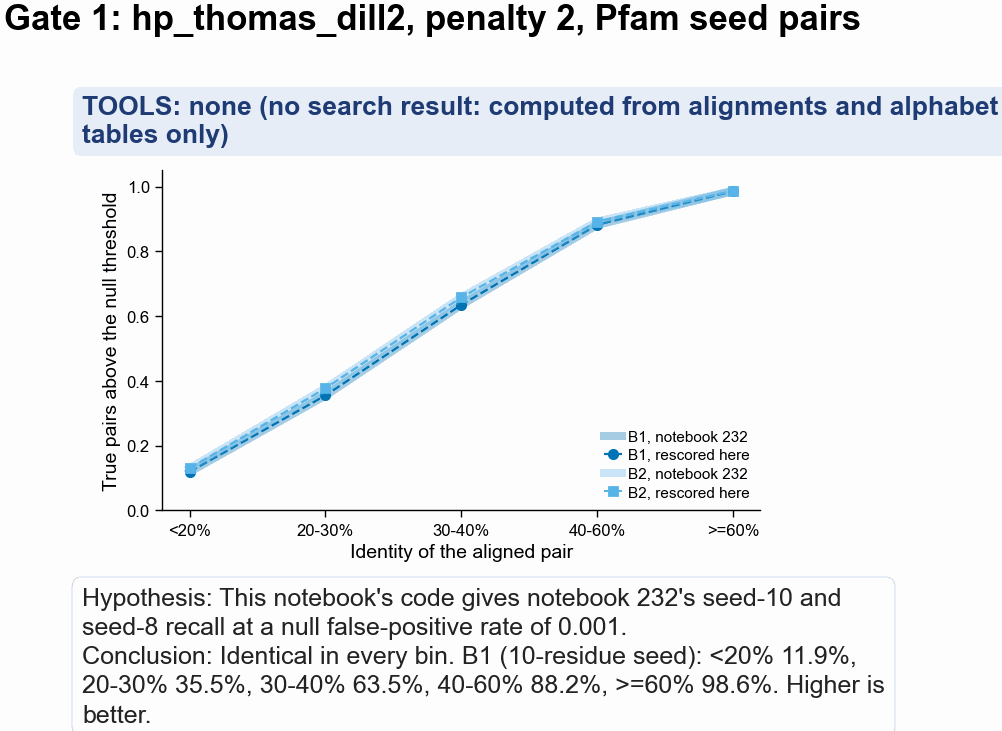

In [2]:
real_all, null_all, bin_all, pidx_all = lp.score_arrays(d, COLS)
thr_all, rate_all, rec_all = lp.threshold_and_recall(real_all, null_all, bin_all, FPR)

s232 = hc.add_identity_bin(
    pl.read_parquet(NB232).filter(
        (pl.col("dataset") == "pfam")
        & (pl.col("alphabet") == lp.ALPHABET)
        & (pl.col("penalty") == 2.0)
        & pl.col("seed").is_in([8, 10])
    )
)
r232 = se.recall_at_null_quantile(s232, ["seed"], FPR)
same_scores = d.join(
    s232.pivot(on="seed", index=["query", "target", "kind"], values="score"),
    on=["query", "target", "kind"],
).select(
    (pl.col("B1_ext") == pl.col("10")).mean().alias("B1 equal"),
    (pl.col("B2_ext") == pl.col("8")).mean().alias("B2 equal"),
    pl.len(),
)
print("share of the 180,000 comparisons whose score equals 232's stored score:")
print(same_scores)
gate1 = pl.DataFrame(
    {
        "identity_bin": BINS,
        "B1 here": rec_all[:, COLS.index("B1_ext")].round(3),
        "B1 in 232": [
            r232.filter((pl.col("seed") == 10) & (pl.col("identity_bin") == b))[
                "recall"
            ][0]
            for b in BINS
        ],
        "B2 here": rec_all[:, COLS.index("B2_ext")].round(3),
        "B2 in 232": [
            r232.filter((pl.col("seed") == 8) & (pl.col("identity_bin") == b))[
                "recall"
            ][0]
            for b in BINS
        ],
    }
).with_columns(pl.col("B1 in 232").round(3), pl.col("B2 in 232").round(3))
print(gate1)
print(
    f"thresholds: B1 {thr_all[0]:.0f}, B2 {thr_all[1]:.0f}; achieved null rate B1 {rate_all[0]:.5f}, B2 {rate_all[1]:.5f}"
)
gate1_ok = (gate1["B1 here"] == gate1["B1 in 232"]).all() and (
    gate1["B2 here"] == gate1["B2 in 232"]
).all()
print("Gate 1 reproduced to the digit:", gate1_ok)
assert gate1_ok

fig, ax = pf.figure(pf.ONE_COLUMN_MM, 55, layout=None)
x = np.arange(len(BINS))
for name, col232, colhere, mk in [
    ("B1", "B1 in 232", "B1 here", "o"),
    ("B2", "B2 in 232", "B2 here", "s"),
]:
    ax.plot(
        x,
        gate1[col232],
        color=COLOR[name],
        lw=3,
        alpha=0.35,
        label=f"{name}, notebook 232",
    )
    ax.plot(
        x,
        gate1[colhere],
        color=COLOR[name],
        marker=mk,
        ms=3,
        lw=0.8,
        ls="--",
        label=f"{name}, rescored here",
    )
ax.set_xticks(x, BINS)
ax.set_xlabel("Identity of the aligned pair")
ax.set_ylabel("True pairs above the null threshold")
ax.set_ylim(0, 1.05)
ax.legend(loc="lower right", fontsize=5.5)
hc.finish_figure(
    fig,
    FIG / "292_gate1_reproduce_nb232_pfam_seed.png",
    tools=hc.NO_TOOL,
    hypothesis="This notebook's code gives notebook 232's seed-10 and seed-8 recall at a null false-positive rate of 0.001.",
    conclusion=(
        f"Identical in every bin. B1 (10-residue seed): "
        + ", ".join(f"{b} {100 * v:.1f}%" for b, v in zip(BINS, gate1["B1 here"]))
        + ". Higher is better."
    ),
    title="Gate 1: hp_thomas_dill2, penalty 2, Pfam seed pairs",
    wrap=70,
)

## 2. The sweep, on the selection half

72 linked-pair settings (2 ways to pick keys × 4 anchor lengths × 3 window sizes × 3 gap
rules), each scored with extension. Recall at 20–30% identity at the 0.001 threshold, on a
random half of the true pairs and their own shuffled nulls. The setting with the highest
value is chosen here and only evaluated in section 4. Every square is one setting; the
chosen one is outlined.

selection half 30_000 pairs, report half 30_000 pairs


selection half, 20-30% bin: B1 0.384, B2 0.375
chosen: all_a6_g32_none; best one-partner-per-position setting: rand_a6_g32_none
shape: (72, 8)
┌──────────────────────┬──────┬────────┬─────────┬──────────┬───────────┬───────────┬──────────────┐
│ setting              ┆ mode ┆ anchor ┆ gap_max ┆ gap_rule ┆ threshold ┆ null_rate ┆ recall_20_30 │
│ ---                  ┆ ---  ┆ ---    ┆ ---     ┆ ---      ┆ ---       ┆ ---       ┆ ---          │
│ str                  ┆ str  ┆ i64    ┆ i64     ┆ str      ┆ f64       ┆ f64       ┆ f64          │
╞══════════════════════╪══════╪════════╪═════════╪══════════╪═══════════╪═══════════╪══════════════╡
│ all_a6_g32_none      ┆ all  ┆ 6      ┆ 32      ┆ none     ┆ 29.0      ┆ 0.00097   ┆ 0.464        │
│ all_a7_g32_none      ┆ all  ┆ 7      ┆ 32      ┆ none     ┆ 28.0      ┆ 0.00098   ┆ 0.46         │
│ all_a6_g16_none      ┆ all  ┆ 6      ┆ 16      ┆ none     ┆ 27.0      ┆ 0.00097   ┆ 0.446        │
│ all_a8_g32_none      ┆ all  ┆ 8      ┆ 32      

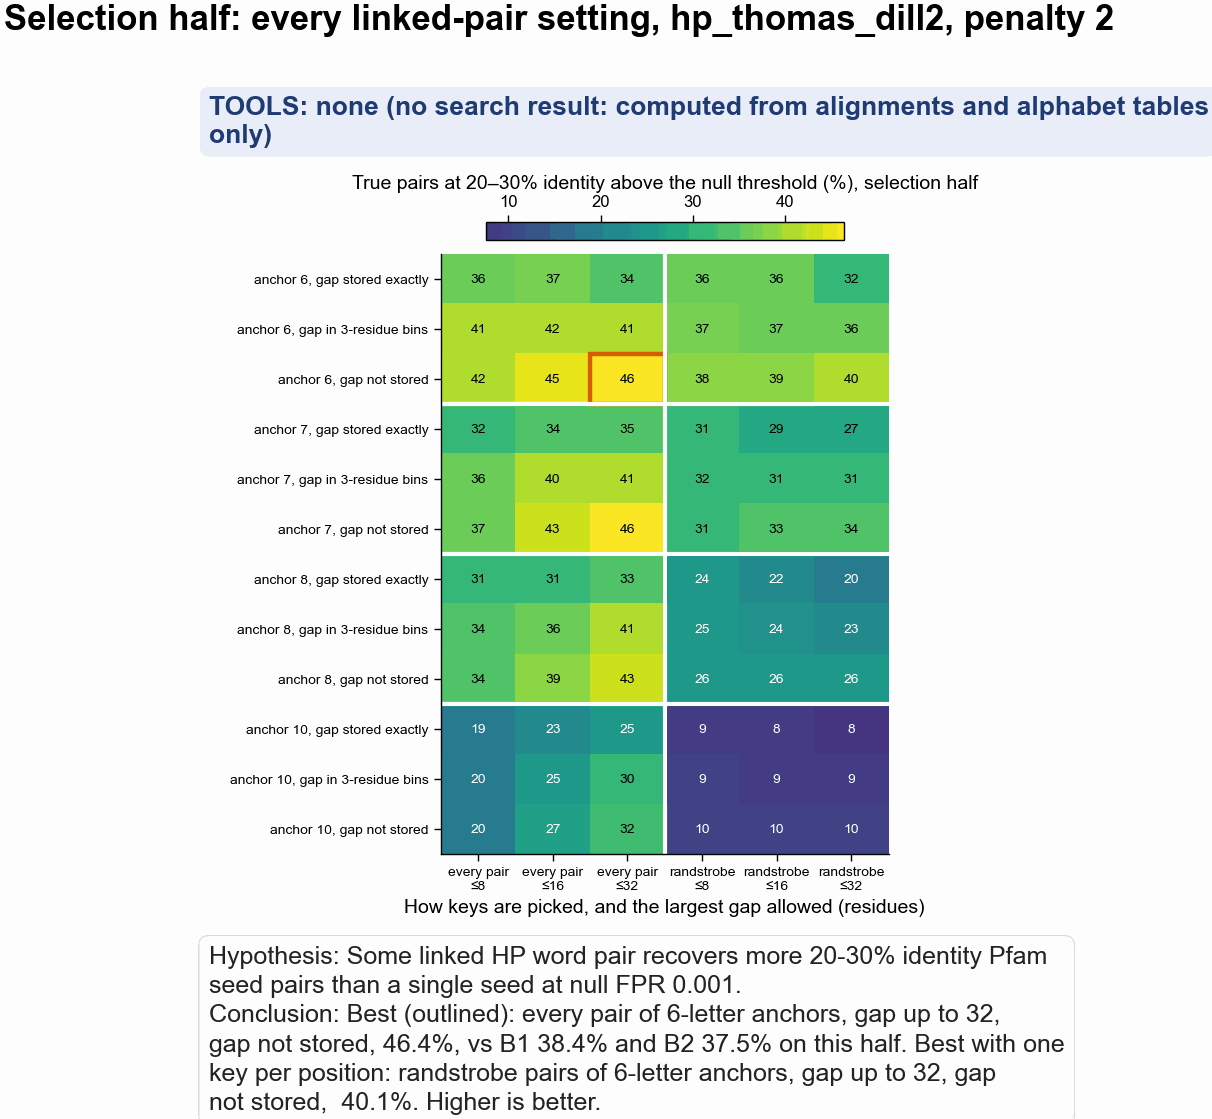

In [3]:
rng = np.random.default_rng(SPLIT_SEED)
perm = rng.permutation(np.unique(pidx_all))
select_ids = np.sort(perm[: perm.size // 2])
is_select = np.isin(pidx_all, select_ids)
print(
    f"selection half {is_select.sum():_} pairs, report half {(~is_select).sum():_} pairs"
)

real_s, null_s, bin_s = real_all[is_select], null_all[is_select], bin_all[is_select]
thr_s, rate_s, rec_s = lp.threshold_and_recall(real_s, null_s, bin_s, FPR)
b2030 = BINS.index("20-30%")
sweep = pl.DataFrame(
    {
        "setting": LINKED,
        "mode": [s[0] for s in lp.ALL_SETTINGS],
        "anchor": [s[1] for s in lp.ALL_SETTINGS],
        "gap_max": [s[2] for s in lp.ALL_SETTINGS],
        "gap_rule": [s[3] for s in lp.ALL_SETTINGS],
        "threshold": [thr_s[COLS.index(f"{s}_ext")] for s in LINKED],
        "null_rate": [rate_s[COLS.index(f"{s}_ext")] for s in LINKED],
        "recall_20_30": [rec_s[b2030, COLS.index(f"{s}_ext")] for s in LINKED],
    }
).sort("recall_20_30", descending=True)
CHOSEN = sweep["setting"][0]
CHOSEN_RAND = sweep.filter(pl.col("mode") == "rand")["setting"][0]
base_sel = {n: rec_s[b2030, COLS.index(f"{n}_ext")] for n in ["B1", "B2"]}
print(f"selection half, 20-30% bin: B1 {base_sel['B1']:.3f}, B2 {base_sel['B2']:.3f}")
print(f"chosen: {CHOSEN}; best one-partner-per-position setting: {CHOSEN_RAND}")
print(sweep.with_columns(pl.col("recall_20_30").round(3), pl.col("null_rate").round(5)))

# heatmap: rows = anchor length x gap rule, columns = key choice x window
rows_ = [(a, t) for a in lp.ANCHOR_LENGTHS for t in lp.TREATMENTS]
cols_ = [(m, g) for m in lp.MODES for g in lp.GAP_MAXES]
H = np.array(
    [
        [
            sweep.filter(pl.col("setting") == lp.setting_name(m, a, g, t))[
                "recall_20_30"
            ][0]
            for (m, g) in cols_
        ]
        for (a, t) in rows_
    ]
)
fig, ax = pf.figure(pf.ONE_COLUMN_MM, 105, layout=None)
cmap = mpl.colors.ListedColormap(plt.cm.viridis(np.linspace(0.15, 1, 256)))
im = ax.imshow(
    H * 100, cmap=cmap, aspect="auto", vmin=H.min() * 100, vmax=H.max() * 100
)
for i in range(H.shape[0]):
    for j in range(H.shape[1]):
        v = 100 * H[i, j]
        ax.text(
            j,
            i,
            f"{v:.0f}",
            ha="center",
            va="center",
            fontsize=5,
            color="white" if v < (H.min() + H.max()) * 50 else "black",
        )
for m, a, g, t in [s for s in lp.ALL_SETTINGS if lp.setting_name(*s) == CHOSEN]:
    ax.add_patch(
        Rectangle(
            (cols_.index((m, g)) - 0.5, rows_.index((a, t)) - 0.5),
            1,
            1,
            fill=False,
            ec=COLOR["linked"],
            lw=1.6,
            clip_on=False,
        )
    )
ax.set_xticks(
    range(len(cols_)),
    [f"{'every pair' if m == 'all' else 'randstrobe'}\n≤{g}" for m, g in cols_],
    fontsize=5,
)
ax.set_yticks(
    range(len(rows_)), [f"anchor {a}, {TREAT_LABEL[t]}" for a, t in rows_], fontsize=5
)
ax.set_xlabel("How keys are picked, and the largest gap allowed (residues)")
for k in range(1, len(lp.ANCHOR_LENGTHS)):
    ax.axhline(k * len(lp.TREATMENTS) - 0.5, color="white", lw=1.5)
ax.axvline(len(lp.GAP_MAXES) - 0.5, color="white", lw=1.5)
cb = fig.colorbar(im, ax=ax, location="top", shrink=0.8, pad=0.02)
cb.set_label(
    "True pairs at 20–30% identity above the null threshold (%), selection half"
)
hc.finish_figure(
    fig,
    FIG / "292_sweep_recall_20_30_selection_half_pfam_seed.png",
    tools=hc.NO_TOOL,
    hypothesis="Some linked HP word pair recovers more 20-30% identity Pfam seed pairs than a single seed at null FPR 0.001.",
    conclusion=(
        f"Best (outlined): {plain(CHOSEN)}, {100 * sweep['recall_20_30'][0]:.1f}%, vs B1 {100 * base_sel['B1']:.1f}% and B2 {100 * base_sel['B2']:.1f}% on this half. "
        f"Best with one key per position: {plain(CHOSEN_RAND)},  {100 * sweep.filter(pl.col('setting') == CHOSEN_RAND)['recall_20_30'][0]:.1f}%. Higher is better."
    ),
    title="Selection half: every linked-pair setting, hp_thomas_dill2, penalty 2",
    wrap=75,
    header_y=0.955,
)

## 3. What one key looks like on a real pair

One true pair from the report half at 20–30% identity, picked by a rule written before
looking: among pairs where the chosen setting scores above its threshold and B1 and B2 both
do not, keep those whose best key spans an insertion or deletion (query gap ≠ target gap),
then take the shortest alignment. Rows per block: query residues, query HP classes (H =
`ACFILMVWY`, P = `DEGHKNPQRST`), `|` where the two classes match, target HP classes, target
residues. The two boxes are the anchors of the best-scoring key; the bracket under them is
the gap; the black bar marks the longest run of matching HP classes, the longest exact HP
word the two share.

report-half 20-30% pairs found by the chosen setting but by neither B1 nor B2: 709 of 7_512
634 of them have a best key across an insertion or deletion
PF06522: Q5KPW0_CRYNJ/11-63 vs M3ZJB0_XIPMA/35-88; 13 of 53 aligned columns identical (25%), 44 of 53 with matching HP classes
best key: anchors of 6 at alignment columns 3 and 29; gap 19 residues in the query, 20 in the target; key score 32 (threshold 30); 88 shared keys
B1 score 21, B2 score 21 (threshold 22); longest shared HP run 12 residues


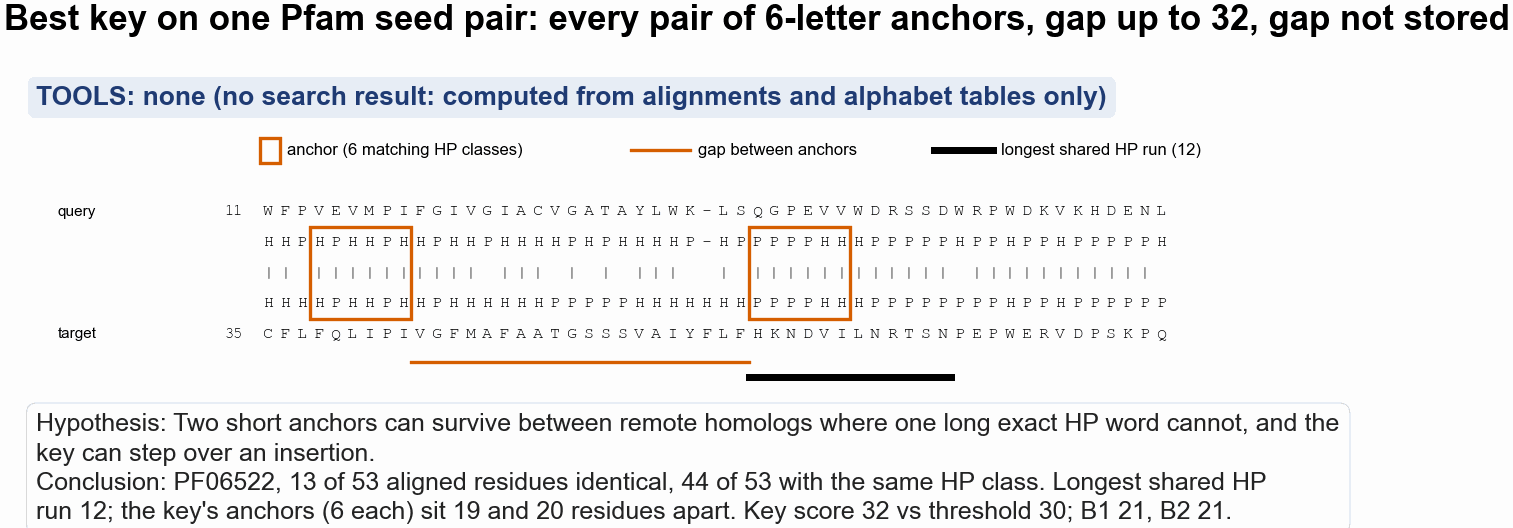

In [4]:
m_c, a_c, g_c, t_c = next(s for s in lp.ALL_SETTINGS if lp.setting_name(*s) == CHOSEN)
c_ext = COLS.index(f"{CHOSEN}_ext")
rep = ~is_select
thr_rep, _, _ = lp.threshold_and_recall(real_all[rep], null_all[rep], bin_all[rep], FPR)
cand = (
    rep
    & (bin_all == b2030)
    & (real_all[:, c_ext] > thr_rep[c_ext])
    & (real_all[:, COLS.index("B1_ext")] <= thr_rep[COLS.index("B1_ext")])
    & (real_all[:, COLS.index("B2_ext")] <= thr_rep[COLS.index("B2_ext")])
)
print(
    f"report-half 20-30% pairs found by the chosen setting but by neither B1 nor B2: {cand.sum():_} "
    f"of {(rep & (bin_all == b2030)).sum():_}"
)
aln = (
    pl.read_parquet(ALN)
    .filter(pl.col("lali") >= 50)
    .sample(n=60_000, seed=0, shuffle=True)
    .with_row_index("pair_index")
    .filter(pl.col("pair_index").is_in(pidx_all[cand].tolist()))
)
ex_rows = []
for r in aln.iter_rows(named=True):
    k = lp.best_key(r["qaln"], r["taln"], m_c, a_c, g_c, t_c)
    if k and k["gap_query"] != k["gap_target"]:
        ex_rows.append({**r, **k})
ex = (
    pl.DataFrame(ex_rows)
    .with_columns(pl.col("qaln").str.len_chars().alias("aln_len"))
    .sort("aln_len", "pair_index")
)
print(f"{ex.height} of them have a best key across an insertion or deletion")
E = ex.row(0, named=True)
row_scores = real_all[np.flatnonzero(pidx_all == E["pair_index"])[0]]
assert E["score"] == row_scores[c_ext], "best_key disagrees with the stored score"

tab = lp.TABLES[lp.ALPHABET]
q, t = E["qaln"], E["taln"]
qc, tc = (
    tab[np.frombuffer(q.encode(), np.uint8)],
    tab[np.frombuffer(t.encode(), np.uint8)],
)
match = (qc == tc) & (qc != lp.GAP) & (tc != lp.GAP)
run = np.diff(np.concatenate(([0], match.astype(int), [0])))
starts, ends = np.flatnonzero(run == 1), np.flatnonzero(run == -1)
lr = int(np.argmax(ends - starts))
run_s, run_e = starts[lr], ends[lr]
aligned = (np.frombuffer(q.encode(), np.uint8) != ord("-")) & (
    np.frombuffer(t.encode(), np.uint8) != ord("-")
)
n_ident = sum(1 for x, y in zip(q, t) if x == y and x != "-")
hp = lambda c: "".join(
    "-" if ch == "-" else ("H" if v == 0 else ("P" if v == 1 else "X"))
    for ch, v in zip(c, tab[np.frombuffer(c.encode(), np.uint8)])
)
q_hp, t_hp = hp(q), hp(t)
mline = "".join("|" if mm else " " for mm in match)
q0 = int(E["query"].split("/")[1].split("-")[0])
t0 = int(E["target"].split("/")[1].split("-")[0])
print(
    f"{E['family']}: {E['query']} vs {E['target']}; {n_ident} of {int(aligned.sum())} aligned columns identical "
    f"({100 * E['seqid_ali']:.0f}%), {int(match.sum())} of {int(aligned.sum())} with matching HP classes"
)
print(
    f"best key: anchors of {a_c} at alignment columns {E['c1']} and {E['c2']}; gap {E['gap_query']} residues in the query, "
    f"{E['gap_target']} in the target; key score {E['score']:.0f} (threshold {thr_rep[c_ext]:.0f}); {E['n_keys']} shared keys"
)
print(
    f"B1 score {row_scores[COLS.index('B1_ext')]:.0f}, B2 score {row_scores[COLS.index('B2_ext')]:.0f} (threshold {thr_rep[COLS.index('B1_ext')]:.0f}); "
    f"longest shared HP run {run_e - run_s} residues"
)

W = 70
nblk = int(np.ceil(len(q) / W))
fig, ax = pf.figure(pf.TWO_COLUMN_MM, 16 + 22 * nblk, layout=None)
ax.set_axis_off()
ax.set_xlim(-12, W + 1)
ax.set_ylim(-nblk * 7.2 + 1.4, 2.6)
mono = dict(family="monospace", fontsize=6, va="center")


def resnum(s, start, upto):
    return start + sum(1 for ch in s[:upto] if ch != "-")


ax.add_patch(Rectangle((0, 1.6), 1.2, 0.8, fill=False, ec=COLOR["linked"], lw=1.2))
ax.text(1.6, 2.0, f"anchor ({a_c} matching HP classes)", fontsize=6, va="center")
ax.plot([22, 25.5], [2.0, 2.0], color=COLOR["linked"], lw=1.2)
ax.text(26, 2.0, "gap between anchors", fontsize=6, va="center")
ax.plot([40, 43.5], [2.0, 2.0], color="black", lw=2.5)
ax.text(44, 2.0, f"longest shared HP run ({run_e - run_s})", fontsize=6, va="center")
for b in range(nblk):
    s, e = b * W, min((b + 1) * W, len(q))
    y0 = -b * 7.2
    for k_, (lab, txt) in enumerate(
        [
            (f"{resnum(q, q0, s)}", q[s:e]),
            ("", q_hp[s:e]),
            ("", mline[s:e]),
            ("", t_hp[s:e]),
            (f"{resnum(t, t0, s)}", t[s:e]),
        ]
    ):
        y = y0 - k_
        ax.text(-1, y, lab, ha="right", **{**mono, "fontsize": 5.5})
        for i, ch in enumerate(txt):
            ax.text(i + 0.5, y, ch, ha="center", **mono)
    ax.text(-12, y0, "query", fontsize=5.5, va="center")
    ax.text(-12, y0 - 4, "target", fontsize=5.5, va="center")
    for cstart in (E["c1"], E["c2"]):
        lo, hi = max(cstart, s), min(cstart + a_c, e)
        if lo < hi:
            ax.add_patch(
                Rectangle(
                    (lo - s, y0 - 3.5),
                    hi - lo,
                    3.0,
                    fill=False,
                    ec=COLOR["linked"],
                    lw=1.2,
                )
            )
    lo, hi = max(E["c1"] + a_c, s), min(E["c2"], e)
    if lo < hi:
        ax.plot([lo - s, hi - s], [y0 - 4.9, y0 - 4.9], color=COLOR["linked"], lw=1.2)
    lo, hi = max(run_s, s), min(run_e, e)
    if lo < hi:
        ax.plot([lo - s, hi - s], [y0 - 5.4, y0 - 5.4], color="black", lw=2.5)
hc.finish_figure(
    fig,
    FIG / "292_example_linked_key_pfam_seed_pair.png",
    tools=hc.NO_TOOL,
    hypothesis="Two short anchors can survive between remote homologs where one long exact HP word cannot, and the key can step over an insertion.",
    conclusion=(
        f"{E['family']}, {n_ident} of {int(aligned.sum())} aligned residues identical, {int(match.sum())} of {int(aligned.sum())} with the same HP class. Longest shared HP run {run_e - run_s}; the key's anchors ({a_c} each) sit "
        f"{E['gap_query']} and {E['gap_target']} residues apart. Key score {E['score']:.0f} vs threshold {thr_rep[c_ext]:.0f}; B1 {row_scores[COLS.index('B1_ext')]:.0f}, B2 {row_scores[COLS.index('B2_ext')]:.0f}."
    ),
    title=f"Best key on one Pfam seed pair: {plain(CHOSEN)}",
    wrap=110,
)

## 4. The verdict, on the report half

Recall at the 0.001 threshold per identity bin on the half not used for choosing, for B1,
B2 and the chosen setting with and without extension. Bars are bootstrap 95% intervals
(1,000 resamples of pairs; each true pair is resampled with its own shuffled targets and
the threshold is recomputed each time). The verdict line under the figure is computed from
the same numbers.

shape: (25, 9)
┌──────────────┬───────────────────────┬───────────┬───────────┬──────────────┬──────────────┬────────┬────────┬─────────┐
│ score        ┆ column                ┆ threshold ┆ null_rate ┆ identity_bin ┆ n_true_pairs ┆ recall ┆ ci_low ┆ ci_high │
│ ---          ┆ ---                   ┆ ---       ┆ ---       ┆ ---          ┆ ---          ┆ ---    ┆ ---    ┆ ---     │
│ str          ┆ str                   ┆ f64       ┆ f64       ┆ str          ┆ i64          ┆ f64    ┆ f64    ┆ f64     │
╞══════════════╪═══════════════════════╪═══════════╪═══════════╪══════════════╪══════════════╪════════╪════════╪═════════╡
│ B1           ┆ B1_ext                ┆ 22.0      ┆ 0.0008    ┆ <20%         ┆ 3256         ┆ 0.116  ┆ 0.096  ┆ 0.141   │
│ B1           ┆ B1_ext                ┆ 22.0      ┆ 0.0008    ┆ 20-30%       ┆ 7512         ┆ 0.356  ┆ 0.323  ┆ 0.397   │
│ B1           ┆ B1_ext                ┆ 22.0      ┆ 0.0008    ┆ 30-40%       ┆ 7024         ┆ 0.633  ┆ 0.6    ┆ 0.669   │
│

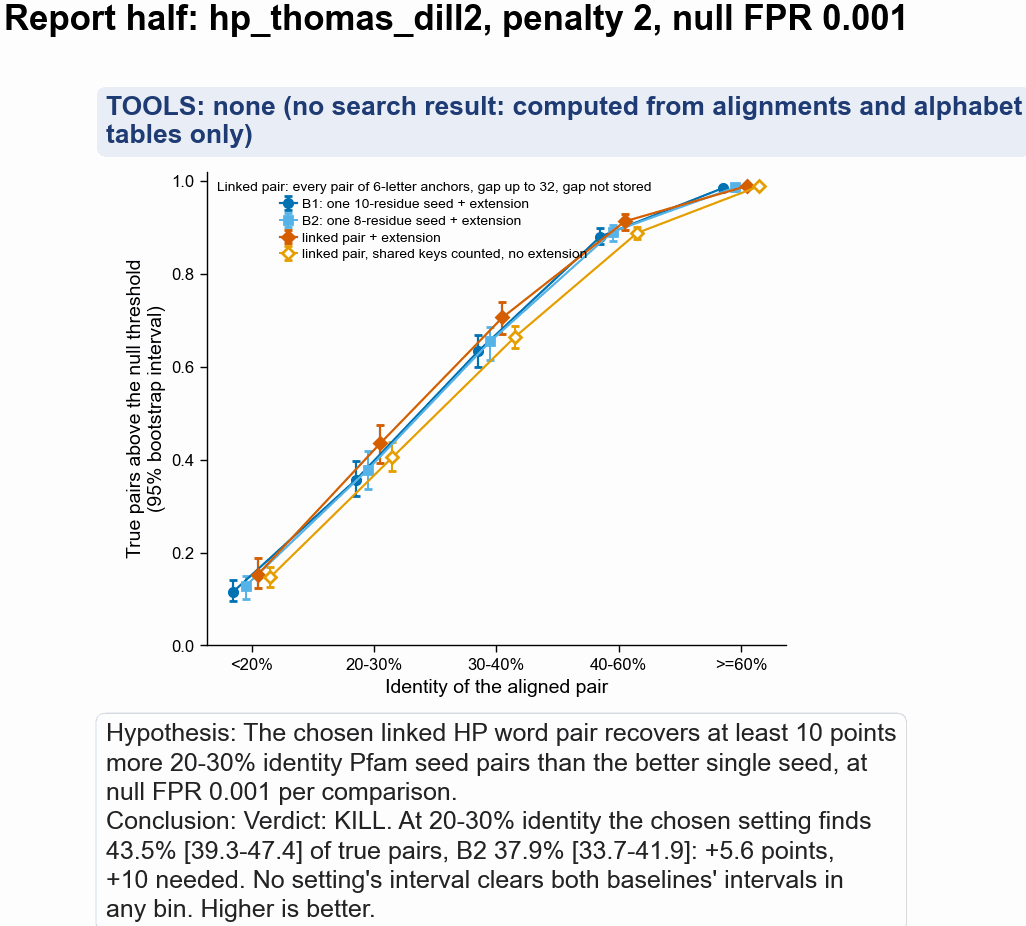

In [5]:
real_r, null_r, bin_r = real_all[rep], null_all[rep], bin_all[rep]
# every linked setting is bootstrapped too: the KILL rule is about any setting, in any bin
EXT = ["B1_ext", "B2_ext"] + [f"{x}_ext" for x in LINKED] + [f"{CHOSEN}_count"]
idx = [COLS.index(c) for c in EXT]
thr_r, rate_r, rec_r = lp.threshold_and_recall(
    real_r[:, idx], null_r[:, :, idx], bin_r, FPR
)
boot = lp.bootstrap_recall(
    real_r[:, idx], null_r[:, :, idx], bin_r, FPR, N_BOOT, seed=1
)
lo, hi = np.percentile(boot, 2.5, axis=0), np.percentile(boot, 97.5, axis=0)
SHOW = {
    "B1": "B1_ext",
    "B2": "B2_ext",
    "linked": f"{CHOSEN}_ext",
    "linked_count": f"{CHOSEN}_count",
    "randstrobe": f"{CHOSEN_RAND}_ext",
}
J = {n: EXT.index(c) for n, c in SHOW.items()}
res = pl.DataFrame(
    [
        {
            "score": n,
            "column": SHOW[n],
            "threshold": thr_r[j],
            "null_rate": rate_r[j],
            "identity_bin": b,
            "n_true_pairs": int((bin_r == i).sum()),
            "recall": rec_r[i, j],
            "ci_low": lo[i, j],
            "ci_high": hi[i, j],
        }
        for n, j in J.items()
        for i, b in enumerate(BINS)
    ]
)
print(
    res.with_columns(
        pl.col("recall", "ci_low", "ci_high").round(3), pl.col("null_rate").round(5)
    )
)

jB1, jB2, jL = J["B1"], J["B2"], J["linked"]
best_base = jB1 if rec_r[b2030, jB1] >= rec_r[b2030, jB2] else jB2
base_name = "B1" if best_base == jB1 else "B2"
gain = rec_r[b2030, jL] - rec_r[b2030, best_base]
pass_rule = gain >= 0.10 and lo[b2030, jL] > hi[b2030, best_base]
base_hi = np.maximum(
    hi[:, jB1], hi[:, jB2]
)  # upper end of the better baseline's interval, per bin
lin = [EXT.index(f"{x}_ext") for x in LINKED]
# reading 1 (the one PASS uses): the setting's interval lies wholly above the baselines' intervals
beats_strict = [
    (LINKED[k], BINS[i])
    for k, j in enumerate(lin)
    for i in range(len(BINS))
    if lo[i, j] > base_hi[i]
]
# reading 2: the setting's own value lies above the baselines' intervals
beats_loose = [
    (LINKED[k], BINS[i])
    for k, j in enumerate(lin)
    for i in range(len(BINS))
    if rec_r[i, j] > base_hi[i]
]
print(
    f"settings x bins whose interval lies wholly above both baselines' intervals: {len(beats_strict)}"
)
print(
    f"settings x bins whose value lies above both baselines' intervals: {len(beats_loose)}"
)
print(
    pl.DataFrame(beats_loose, schema=["setting", "identity_bin"], orient="row")
    .group_by("identity_bin")
    .len()
    .sort("identity_bin")
    if beats_loose
    else "none"
)
if pass_rule:
    VERDICT = "PASS"
elif not beats_strict:
    VERDICT = "KILL"
else:
    VERDICT = "NEITHER PASS NOR KILL"
diff_boot = boot[:, b2030, jL] - boot[:, b2030, best_base]
d_lo, d_hi = np.percentile(diff_boot, [2.5, 97.5])
verdict_line = (
    f"Verdict: {VERDICT}. At 20-30% identity the chosen setting finds {100 * rec_r[b2030, jL]:.1f}% "
    f"[{100 * lo[b2030, jL]:.1f}-{100 * hi[b2030, jL]:.1f}] of true pairs, {base_name} {100 * rec_r[b2030, best_base]:.1f}% "
    f"[{100 * lo[b2030, best_base]:.1f}-{100 * hi[b2030, best_base]:.1f}]: +{100 * gain:.1f} points, +10 needed. "
    f"No setting's interval clears both baselines' intervals in any bin"
    + ("." if not beats_strict else " (false: see above).")
)
print(verdict_line)
print(
    f"Looser reading (a setting's value above the baselines' intervals): {len(beats_loose)} setting-bin cases, so by that reading the result is neither PASS nor KILL. Either way the index stays."
)
print(
    f"Gain of the chosen setting over {base_name} at 20-30%, paired bootstrap (same resamples): {100 * gain:.1f} points, 95% interval {100 * d_lo:.1f} to {100 * d_hi:.1f}"
)
names = list(J)
# why the single-setting intervals are wide: recall at 20-30% one score step either side of the threshold
for n in ["B2", "linked"]:
    j = J[n]
    col = real_r[:, idx[j]][bin_r == b2030]
    nul = null_r[:, :, idx[j]].ravel()
    print(
        f"{n}: "
        + "; ".join(
            f"threshold {t:.0f}: recall {100 * (col > t).mean():.1f}%, null rate {(nul > t).mean():.5f}"
            for t in (thr_r[j] - 1, thr_r[j], thr_r[j] + 1)
        )
    )

fig, ax = pf.figure(pf.ONE_COLUMN_MM, 72, layout=None)
x = np.arange(len(BINS))
style = {
    "B1": ("B1: one 10-residue seed + extension", "o", True),
    "B2": ("B2: one 8-residue seed + extension", "s", True),
    "linked": ("linked pair + extension", "D", True),
    "linked_count": ("linked pair, shared keys counted, no extension", "D", False),
}
off = {"B1": -0.15, "B2": -0.05, "linked": 0.05, "linked_count": 0.15}
for n, (lab, mk, filled) in style.items():
    j = J[n]
    ax.errorbar(
        x + off[n],
        rec_r[:, j],
        yerr=[rec_r[:, j] - lo[:, j], hi[:, j] - rec_r[:, j]],
        color=COLOR[n],
        marker=mk,
        ms=3,
        mfc=COLOR[n] if filled else "white",
        lw=0.8,
        capsize=1.5,
        label=lab,
    )
ax.set_xticks(x, BINS)
ax.set_xlabel("Identity of the aligned pair")
ax.set_ylabel("True pairs above the null threshold\n(95% bootstrap interval)")
ax.set_ylim(0, 1.02)
ax.legend(
    loc="upper left",
    fontsize=5,
    title=f"Linked pair: {plain(CHOSEN)}",
    title_fontsize=5,
)
hc.finish_figure(
    fig,
    FIG / "292_recall_by_identity_report_half_pfam_seed.png",
    tools=hc.NO_TOOL,
    hypothesis="The chosen linked HP word pair recovers at least 10 points more 20-30% identity Pfam seed pairs than the better single seed, at null FPR 0.001 per comparison.",
    conclusion=verdict_line + " Higher is better.",
    title="Report half: hp_thomas_dill2, penalty 2, null FPR 0.001",
    wrap=70,
)

## 5. Bits, measured on Swiss-Prot

How often does a key match by chance? For each setting, every key in Swiss-Prot
(`uniprot_sprot.fasta.gz`, 572,970 proteins, encoded in `hp_thomas_dill2`) is counted, and
the chance that two keys drawn at random are equal is the sum over keys of p(key)². Its
−log2 is the measured number of bits. The prediction drawn as a line assumes one bit per HP
letter, plus log2 of the number of gap values the key stores. The y-axis is the expected
number of chance key matches between two unrelated sequences of 131 residues (the median
domain length of the pairs above), over every pair of positions, not one diagonal.

The stored Swiss-Prot spectra in `~/data/kmerseek-kmer-spectra` were not used: they only
cover words of 15 or more letters and record more distinct HP 15-mers (72,533) than two
letters allow (32,768), so they come from a different encoding. The rates here are counted
from the same Swiss-Prot file directly.

valid HP 15-mers counted in Swiss-Prot: 199_555_063; median pair length 131
single words:
shape: (4, 4)
┌────────┬────────────────┬───────────────┬─────────────────────────┐
│ anchor ┆ predicted_bits ┆ measured_bits ┆ expected_chance_matches │
│ ---    ┆ ---            ┆ ---           ┆ ---                     │
│ i64    ┆ f64            ┆ f64           ┆ f64                     │
╞════════╪════════════════╪═══════════════╪═════════════════════════╡
│ 6      ┆ 6.0            ┆ 5.79          ┆ 301.41                  │
│ 7      ┆ 7.0            ┆ 6.75          ┆ 153.78                  │
│ 8      ┆ 8.0            ┆ 7.71          ┆ 78.61                   │
│ 10     ┆ 10.0           ┆ 9.62          ┆ 20.69                   │
└────────┴────────────────┴───────────────┴─────────────────────────┘
shape: (72, 9)
┌──────┬────────┬─────────┬───────────┬──────────────────┬────────────────┬───────────────┬──────────────────────────┬─────────────────────────┐
│ mode ┆ anchor ┆ gap_max ┆ treatmen

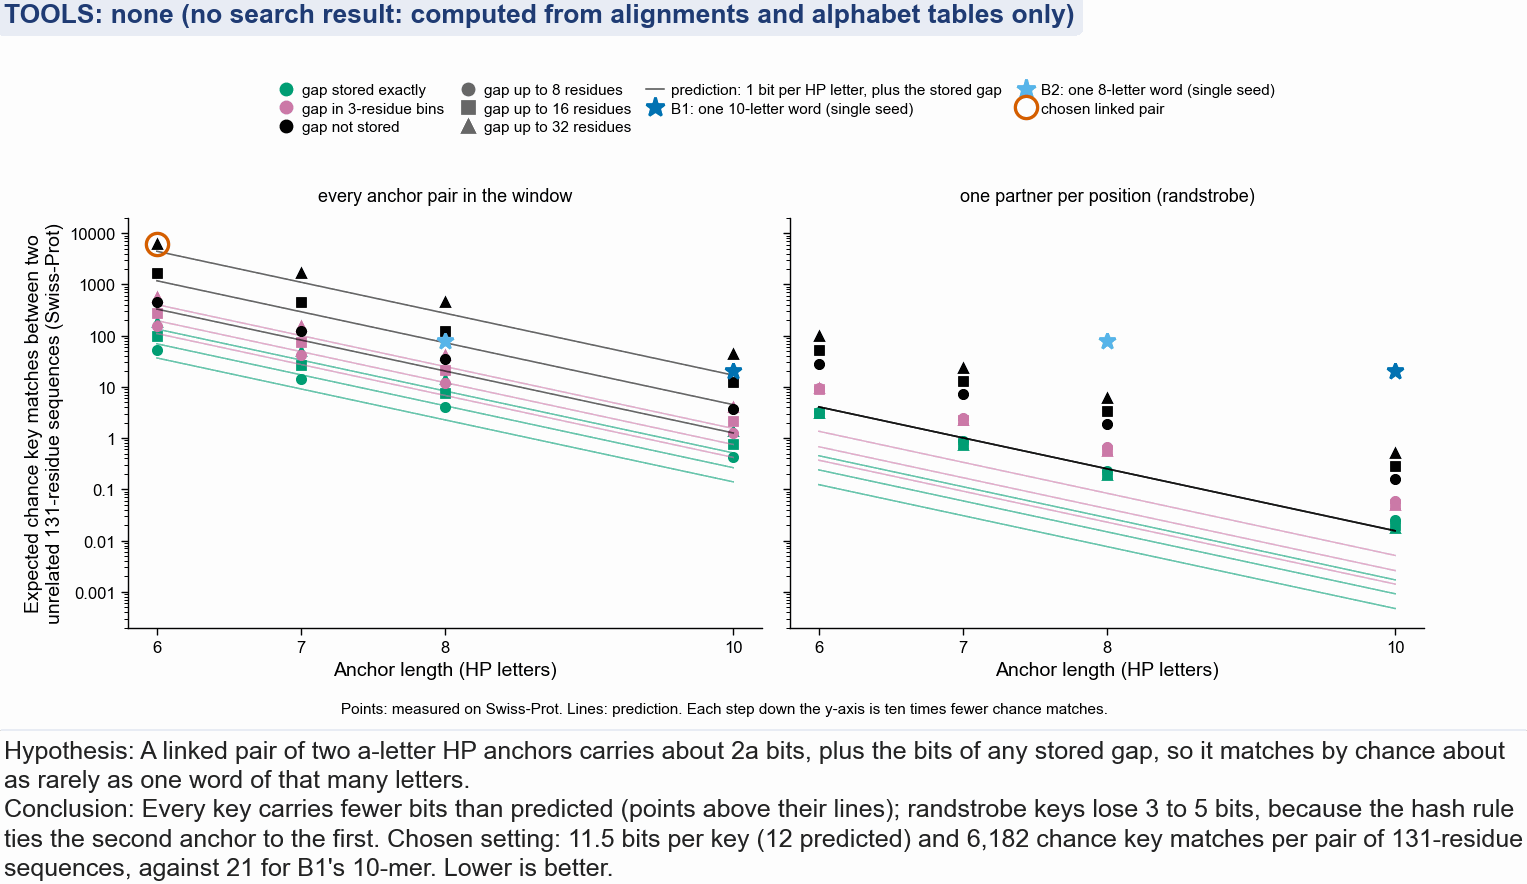

In [6]:
spec = pl.read_parquet(SPECTRUM)
check = spec.filter(pl.col("mode") == "check")
spec = spec.filter(pl.col("mode") != "check").with_columns(
    (
        pl.col("median_length") ** 2
        * pl.col("keys_per_residue") ** 2
        * (2.0 ** -pl.col("predicted_bits"))
    ).alias("predicted_chance_matches"),
    (pl.col("predicted_bits") - pl.col("measured_bits")).alias(
        "bits_short_of_prediction"
    ),
)
L_MED = spec["median_length"][0]
print(
    f"valid HP 15-mers counted in Swiss-Prot: {int(check['rate'][0]):_}; median pair length {L_MED:.0f}"
)
words = spec.filter(pl.col("mode") == "word").select(
    "anchor", "predicted_bits", "measured_bits", "expected_chance_matches"
)
print("single words:")
print(words.with_columns(pl.col("measured_bits", "expected_chance_matches").round(2)))
tabl = (
    spec.filter(pl.col("mode") != "word")
    .select(
        "mode",
        "anchor",
        "gap_max",
        "treatment",
        "keys_per_residue",
        "predicted_bits",
        "measured_bits",
        "bits_short_of_prediction",
        "expected_chance_matches",
    )
    .sort("mode", "gap_max", "treatment", "anchor")
)
print(
    tabl.with_columns(
        pl.col(
            "keys_per_residue",
            "predicted_bits",
            "measured_bits",
            "bits_short_of_prediction",
        ).round(2),
        pl.col("expected_chance_matches").round(3),
    )
)
ch = spec.filter(
    (pl.col("mode") == m_c)
    & (pl.col("anchor") == a_c)
    & (pl.col("gap_max") == g_c)
    & (pl.col("treatment") == t_c)
).row(0, named=True)
w10 = words.filter(pl.col("anchor") == 10).row(0, named=True)
w8 = words.filter(pl.col("anchor") == 8).row(0, named=True)
print(
    f"chosen {CHOSEN}: {ch['measured_bits']:.1f} bits per key measured (prediction {ch['predicted_bits']:.1f}); "
    f"{ch['expected_chance_matches']:.1f} chance key matches per comparison of two {L_MED:.0f}-residue sequences; "
    f"B1's 10-mer {w10['measured_bits']:.1f} bits, {w10['expected_chance_matches']:.1f}; B2's 8-mer {w8['measured_bits']:.1f} bits, {w8['expected_chance_matches']:.1f}"
)

fig, axd = plt.subplot_mosaic(
    [["legend", "legend"], ["all", "rand"]],
    figsize=(pf.TWO_COLUMN_MM * pf.MM, 85 * pf.MM),
    height_ratios=[0.28, 1],
    sharey=False,
)
from matplotlib.lines import Line2D

handles = (
    [
        Line2D([], [], color=COLOR[tr], marker="o", lw=0, ms=4, label=TREAT_LABEL[tr])
        for tr in lp.TREATMENTS
    ]
    + [
        Line2D(
            [], [], color="0.4", marker=mk, lw=0, ms=4, label=f"gap up to {g} residues"
        )
        for g, mk in zip(lp.GAP_MAXES, ["o", "s", "^"])
    ]
    + [
        Line2D(
            [],
            [],
            color="0.4",
            lw=0.6,
            label="prediction: 1 bit per HP letter, plus the stored gap",
        )
    ]
    + [
        Line2D(
            [],
            [],
            color=COLOR[n],
            marker="*",
            ms=7,
            lw=0,
            label=f"{n}: one {a_}-letter word (single seed)",
        )
        for n, a_ in [("B1", 10), ("B2", 8)]
    ]
    + [
        Line2D(
            [],
            [],
            marker="o",
            ms=8,
            mfc="none",
            mec=COLOR["linked"],
            mew=1.2,
            lw=0,
            label="chosen linked pair",
        )
    ]
)
axd["legend"].set_axis_off()
axd["legend"].legend(handles=handles, loc="center", ncol=4, fontsize=5.5, frameon=False)
for mode in lp.MODES:
    ax = axd[mode]
    for tr in lp.TREATMENTS:
        for g, mk in zip(lp.GAP_MAXES, ["o", "s", "^"]):
            s_ = spec.filter(
                (pl.col("mode") == mode)
                & (pl.col("treatment") == tr)
                & (pl.col("gap_max") == g)
            ).sort("anchor")
            ax.plot(
                s_["anchor"],
                s_["predicted_chance_matches"],
                color=COLOR[tr],
                lw=0.6,
                alpha=0.6,
            )
            ax.plot(
                s_["anchor"],
                s_["expected_chance_matches"],
                color=COLOR[tr],
                marker=mk,
                ms=3,
                lw=0,
            )
    for name, a_ in [("B1", 10), ("B2", 8)]:
        r_ = words.filter(pl.col("anchor") == a_)
        ax.plot(
            r_["anchor"],
            r_["expected_chance_matches"],
            marker="*",
            ms=6,
            lw=0,
            color=COLOR[name],
        )
    if mode == m_c:
        ax.plot(
            [a_c],
            [ch["expected_chance_matches"]],
            marker="o",
            ms=8,
            mfc="none",
            mec=COLOR["linked"],
            mew=1.2,
            lw=0,
        )
    ax.set_yscale("log")
    ax.set_ylim(2e-4, 2e4)
    ax.yaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda v, _: f"{v:g}"))
    ax.set_xticks(lp.ANCHOR_LENGTHS)
    ax.set_xlabel("Anchor length (HP letters)")
    ax.set_title(MODE_LABEL[mode], fontsize=6.5)
axd["all"].set_ylabel(
    "Expected chance key matches between two\nunrelated 131-residue sequences (Swiss-Prot)"
)
axd["rand"].set_yticklabels([])
fig.text(
    0.5,
    -0.02,
    "Points: measured on Swiss-Prot. Lines: prediction. Each step down the y-axis is ten times fewer chance matches.",
    ha="center",
    fontsize=5.5,
)
hc.finish_figure(
    fig,
    FIG / "292_chance_key_matches_swissprot.png",
    tools=hc.NO_TOOL,
    hypothesis="A linked pair of two a-letter HP anchors carries about 2a bits, plus the bits of any stored gap, so it matches by chance about as rarely as one word of that many letters.",
    conclusion=(
        f"Every key carries fewer bits than predicted (points above their lines); randstrobe keys lose 3 to 5 bits, because the hash rule ties the second anchor to the first. "
        f"Chosen setting: {ch['measured_bits']:.1f} bits per key ({ch['predicted_bits']:.0f} predicted) and {ch['expected_chance_matches']:,.0f} chance key matches per pair of {L_MED:.0f}-residue sequences, "
        f"against {w10['expected_chance_matches']:.0f} for B1's 10-mer. Lower is better."
    ),
    footer_y=-0.06,
    wrap=140,
)

## 6. Summary and what this does not show

In [7]:
print(verdict_line)
print()
print("Report half, recall at null FPR 0.001 (95% bootstrap interval):")
for n in ["B1", "B2", "linked", "linked_count", "randstrobe"]:
    j = J[n]
    print(
        f"  {n:13s} {SHOW[n]:28s} "
        + "  ".join(
            f"{b} {100 * rec_r[i, j]:.1f} [{100 * lo[i, j]:.1f}-{100 * hi[i, j]:.1f}]"
            for i, b in enumerate(BINS)
        )
    )
print()
print(
    f"False pairs per query at 0.001 per comparison against Swiss-Prot: {FPR * SWISSPROT_PROTEINS:.0f}"
)

Verdict: KILL. At 20-30% identity the chosen setting finds 43.5% [39.3-47.4] of true pairs, B2 37.9% [33.7-41.9]: +5.6 points, +10 needed. No setting's interval clears both baselines' intervals in any bin.

Report half, recall at null FPR 0.001 (95% bootstrap interval):
  B1            B1_ext                       <20% 11.6 [9.6-14.1]  20-30% 35.6 [32.3-39.7]  30-40% 63.3 [60.0-66.9]  40-60% 88.0 [86.4-89.8]  >=60% 98.4 [97.9-98.9]
  B2            B2_ext                       <20% 12.8 [10.0-15.0]  20-30% 37.9 [33.7-41.9]  30-40% 65.4 [61.4-68.6]  40-60% 89.1 [87.1-90.6]  >=60% 98.6 [97.9-99.0]
  linked        all_a6_g32_none_ext          <20% 15.3 [12.3-18.8]  20-30% 43.5 [39.3-47.4]  30-40% 70.6 [67.0-73.9]  40-60% 91.3 [89.5-92.8]  >=60% 98.9 [98.5-99.4]
  linked_count  all_a6_g32_none_count        <20% 14.6 [12.6-16.9]  20-30% 40.5 [37.6-43.7]  30-40% 66.4 [63.9-68.9]  40-60% 88.8 [87.5-90.0]  >=60% 98.9 [98.4-99.2]
  randstrobe    rand_a6_g32_none_ext         <20% 14.6 [13.1-16.9]

Every number below is printed by a cell above.

1. **Gate 1 passed.** This notebook's code gives notebook 232's score on all 180,000
   comparisons and its seed-10 recall in every identity bin: 11.9%, 35.5%, 63.5%, 88.2% and
   98.6%.
2. **Verdict: KILL, and in any case not PASS.** On the report half, the chosen setting
   (every pair of 6-letter HP anchors up to 32 residues apart, gap not stored) finds 43.5%
   (95% interval 39.3–47.4) of the 20–30% identity pairs; the 8-residue seed (B2) finds
   37.9% (33.7–41.9) and the 10-residue seed (B1) 35.6% (32.3–39.7). The gain is 5.6 points
   and the rule asked for 10. No setting's interval lies wholly above both baselines'
   intervals in any identity bin (0 of 72 settings × 5 bins), which is the KILL condition
   read the way the PASS condition is written. Read more loosely (a setting's own value above
   the baselines' intervals), 9 setting–bin cases qualify and the result is "neither". Both
   readings mean the same thing: kmerseek's index stays as it is.
3. **The gain is real but small.** A paired bootstrap of the chosen setting minus B2 at
   20–30% identity gives 5.6 points (2.4 to 9.4). The single-setting intervals are wide
   because the threshold is a whole number and moves by one between resamples, which moves
   recall by several points.
4. **What wins is BLAST's two-hit rule, not an index key.** The best setting keeps every
   anchor pair and stores no gap. That is two short exact matches on the alignment, each
   extended, which may sit on either side of an insertion. With extension switched off (shared keys
   only counted), it finds 40.5% (37.6–43.7). With one key per position, the version an
   index can afford (randstrobe pairs of 6-letter anchors up to 32 apart, gap not stored), it
   finds 40.0% (38.6–42.9), 2 points above B2.
5. **Bits, measured on Swiss-Prot.** Every HP key carries fewer bits than one per letter.
   Keys built from every anchor pair fall 0.5 to 1.6 bits short of the prediction.
   Randstrobe keys fall 2.8 to 5.2 bits short, because the hash rule ties the second anchor
   to the first. The chosen key carries 11.5 bits (12 predicted) and gives about 6,182 chance
   key matches between two unrelated 131-residue sequences, against 21 for B1's 10-letter
   word and 79 for B2's 8-letter word. The randstrobe key carries 7.4 bits and gives about
   96, close to B2's load for 2 points more recall.
6. **Not shown here.** All numbers are per comparison, on each pair's own alignment, against
   a null that keeps composition. A false-positive rate of 0.001 per comparison is about 573
   false pairs per query against Swiss-Prot's 572,970 proteins, so a pass here would have
   been necessary, not sufficient. Database-scale false positives, chance key matches off
   the alignment's diagonal, SCOPe pairs and other alphabets were not tested. Three anchors
   were not tried, because two did not pass.